# Amazon Fine Food Reviews - MongoDB Homework
## Sistemi Informativi Evoluti e Big Data - A.A. 2025-2026

Questo notebook implementa l'analisi completa del dataset [Amazon Fine Food Reviews](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews) utilizzando MongoDB.

## Setup - Installazione delle librerie necessarie

In [82]:
# Importazione delle librerie necessarie

# Librerie per data manipulation e analisi numerica
import pandas as pd
import numpy as np

# Database
from pymongo import MongoClient

# Visualizzazione
import matplotlib.pyplot as plt

# Analisi del sentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Machine Learning e NLP
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

# Utilità Python standard
import time
import warnings

# Configurazione
warnings.filterwarnings('ignore')

## 1. Caricamento dei Dati

Carichiamo il dataset e lo organizziamo in collezioni separate per ogni livello di score (1-5) e una collezione per i record senza testo.

In [83]:
# Connessione a MongoDB
client = MongoClient('mongodb://localhost:27017/')
db = client['amazon_food_reviews']

print("Connesso a MongoDB con successo")
print(f"Database: {db.name}")

Connesso a MongoDB con successo
Database: amazon_food_reviews


In [84]:
# Pulizia per esecuzioni ripetute
db.drop_collection("score_1")
db.drop_collection("score_2")
db.drop_collection("score_3")
db.drop_collection("score_4")
db.drop_collection("score_5")
db.drop_collection("no_text")

{'nIndexesWas': 6, 'ns': 'amazon_food_reviews.no_text', 'ok': 1.0}

## 2. Sentiment Analysis

Utilizziamo VADER (Valence Aware Dictionary and sEntiment Reasoner) per analizzare il sentiment delle recensioni.

In [85]:
analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    """
    Analizza il sentiment di un testo usando VADER
    e lo classifica come richiesto.
    """
    # VADER calcola un punteggio 'compound' da -1 (neg) a +1 (pos)
    compound_score = analyzer.polarity_scores(text)['compound']
    
    # Classificazione secondo le soglie ottenute da Grid Search su 50k campioni (10k per score)
    if compound_score >= 0.53:
        return "positive"
    elif compound_score <= -0.20:
        return "negative"
    else:
        return "neutral"

### Preparazione dati

In [86]:
# carica SOLO le colonne che servono dal CSV
COLUMNS_TO_LOAD = [
    'ProductId', 'UserId', 'ProfileName', 
    'Score', 'Summary', 'Text', 'Time'
]

# definisce la mappatura per rinominare le colonne
COLUMN_MAP = {
    'ProductId': 'product_id',
    'UserId': 'user_id',
    'ProfileName': 'profile_name',
    'Score': 'score',
    'Summary': 'summary',
    'Text': 'text',
    'Time': 'time'
}

# Caricamento e Preparazione Dati (in Pandas)
print("Caricamento Reviews.csv...")
# Carica SOLO le colonne necessarie
df = pd.read_csv("Reviews.csv", usecols=COLUMNS_TO_LOAD)
# Rinomina le colonne
df.rename(columns=COLUMN_MAP, inplace=True)

# Pulizia 'Score' -> solo Intger
df['score'] = pd.to_numeric(df['score'], errors='coerce').astype('Int8')
# Pulizia 'Summary' e 'Text' -> solo String
df['summary'] = df['summary'].fillna('').astype(str)
df['text'] = df['text'].fillna('').astype(str)
# Conversione 'Time' -> Secondi trascorsi dal 01/01/1970
df['time'] = pd.to_datetime(df['time'], unit='s', errors='coerce')

# Analisi Sentiment
print("Esecuzione Analisi del Sentiment (VADER)...")
start_time = time.time()
df['sentiment'] = df['text'].apply(get_sentiment)
elapsed = time.time() - start_time

print(f"Analisi del Sentiment completata in {elapsed:.2f} secondi.")
print("Dati preparati.")

Caricamento Reviews.csv...
Esecuzione Analisi del Sentiment (VADER)...
Analisi del Sentiment completata in 153.46 secondi.
Dati preparati.


### Approccio 1: ETL (Extract, Transform, Load) (Pandas)

In [ ]:
# Creazione delle 6 collezioni
col_score_1 = db["score_1"]
col_score_2 = db["score_2"]
col_score_3 = db["score_3"]
col_score_4 = db["score_4"]
col_score_5 = db["score_5"]
col_no_text = db["no_text"] # Per recensioni senza testo

# Mappa per un accesso più semplice
collections_map = {
    1: col_score_1,
    2: col_score_2,
    3: col_score_3,
    4: col_score_4,
    5: col_score_5,
}

# Filtro e Separazione Dati

# Filtro per 'no_text'
mask_no_text = (df['summary'].str.len() == 0) | (df['text'].str.len() == 0)
# Filtro per score non validi (non 1-5)
mask_invalid_score = ~df['score'].isin([1, 2, 3, 4, 5])
# Dati da inserire in 'col_no_text'
df_invalid = df[mask_no_text | mask_invalid_score]
# Dati validi da smistare nelle collezioni 'score_X'
df_valid = df[~(mask_no_text | mask_invalid_score)]

print(f"Trovati {len(df_invalid)} record per 'col_no_text'.")
print(f"Trovati {len(df_valid)} record validi da smistare.")

# Caricamento Bulk in MongoDB

start_time = time.time()
# Inserimento dati 'no_text'
if not df_invalid.empty:
    try:
        invalid_docs = df_invalid.to_dict('records')
        col_no_text.insert_many(invalid_docs, ordered=False)
        print(f"Inseriti {len(invalid_docs)} documenti in '{col_no_text.name}'.")
    except Exception as e:
        print(f"Errore inserimento bulk in '{col_no_text.name}': {e}")

# Inserimento dati validi (1-5)
for score, collection in collections_map.items():
    df_subset = df_valid[df_valid['score'] == score]
    
    if df_subset.empty:
        print(f"Nessun documento per score {score}.")
        continue
        
    try:
        docs_to_insert = df_subset.to_dict('records')
        collection.insert_many(docs_to_insert, ordered=False)
        print(f"Inseriti {len(docs_to_insert)} documenti in '{collection.name}'")
    except Exception as e:
        print(f"Errore inserimento bulk in '{collection.name}': {e}")

elapsed = time.time() - start_time
print("\nCaricamento completato con ETL")
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

### Approccio 2: Validator

In [ ]:
# Validator secondo lo schema richiesto dalla consegna
# Lo score deve essere obbligatorio per poter classificare le recensioni
# summary e text devono essere stringhe non vuote altrimenti classifico in "no_text"

review_validator = {
    '$jsonSchema': {
        'bsonType': 'object',
        'required': ['score', 'summary', 'text'],
        'properties': {
            'score': {
                'bsonType': 'int',
                'minimum': 1,
                'maximum': 5,
            },
            'summary': {
                'bsonType': 'string',
                "minLength": 1
            },
            'text': {
                'bsonType': 'string',
                "minLength": 1
            }
        }
    }
}

col_score_1 = db.create_collection("score_1", validator=review_validator)
col_score_2 = db.create_collection("score_2", validator=review_validator)
col_score_3 = db.create_collection("score_3", validator=review_validator)
col_score_4 = db.create_collection("score_4", validator=review_validator)
col_score_5 = db.create_collection("score_5", validator=review_validator)
col_no_text = db.create_collection("no_text")

reviews = df.to_dict(orient="records")

start_time = time.time()

for review in reviews:
    score = int(review.get("score"))
    if score == 1:
        try:
            col_score_1.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 2:
        try:
            col_score_2.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 3:
        try:
            col_score_3.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 4:
        try:
            col_score_4.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 5:
        try:
            col_score_5.insert_one(review)
        except:
            col_no_text.insert_one(review)
    else:
        col_no_text.insert_one(review)

elapsed = time.time() - start_time
print("Caricamento completato con Validator")
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

## 3. Interrogazioni Analitiche

### Query 1: Numero di recensioni per ciascun valore di score

Numero di recensioni per score:

Score 1:   52268 recensioni
Score 2:   29744 recensioni
Score 3:   42638 recensioni
Score 4:   80655 recensioni
Score 5:  363122 recensioni


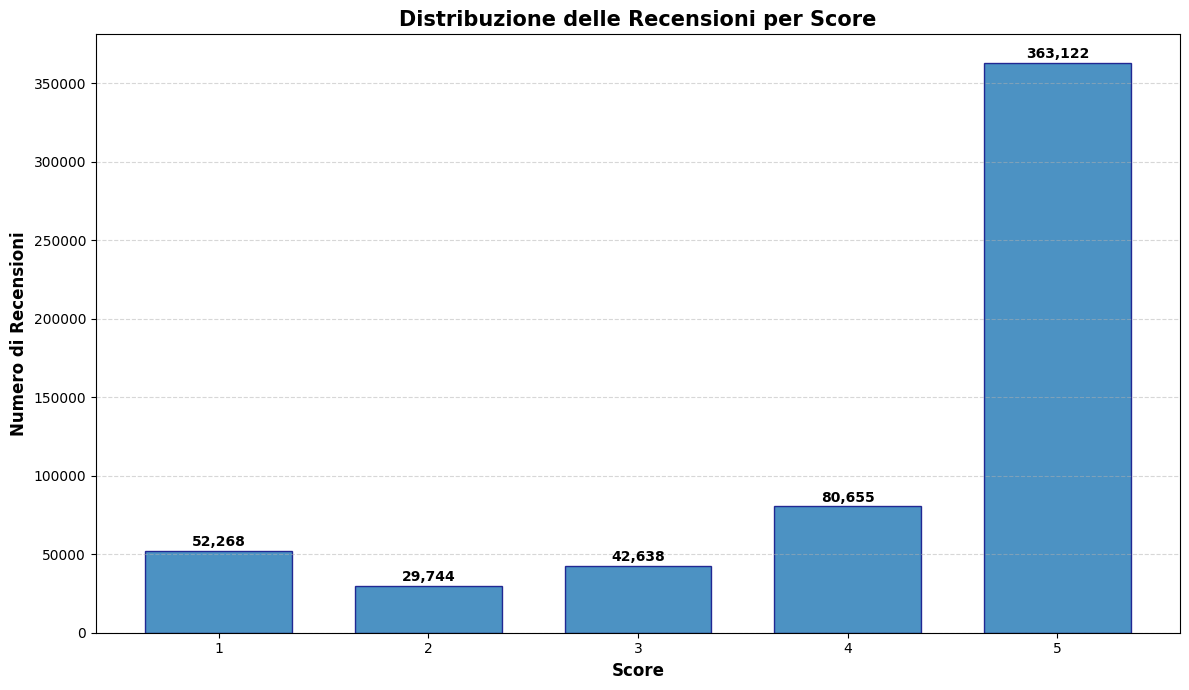

In [90]:
# Query 1: Numero di recensioni per score
score_counts = {}
for i in range(1, 6):
    count = db[f'score_{i}'].count_documents({})
    score_counts[i] = count

print("Numero di recensioni per score:\n")
for score, count in sorted(score_counts.items()):
    print(f"Score {score}: {count:7d} recensioni")

# Visualizzazione con istogramma
fig, ax = plt.subplots(figsize=(12, 7))
scores = list(score_counts.keys())
counts = list(score_counts.values())

bars = ax.bar(scores, counts, edgecolor='navy', alpha=0.8, width=0.7)

# Aggiungi valori sopra le barre
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1000,
            f'{int(height):,}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Numero di Recensioni', fontsize=12, fontweight='bold')
ax.set_title('Distribuzione delle Recensioni per Score', fontsize=15, fontweight='bold')
ax.set_xticks(scores)
ax.grid(axis='y', alpha=0.5, linestyle='--')
plt.tight_layout()
plt.show()

### Query 2: Top 5 prodotti con la media di score più alta

In [91]:
# Query 2: top 5 prodotti 'score'

# Pipeline di aggregazione che unisce tutte le collezioni e calcola medie
pipeline = [
    # Unisci tutte le collezioni score_2 attraverso score_5
    {"$unionWith": {"coll": "score_2"}},
    {"$unionWith": {"coll": "score_3"}},
    {"$unionWith": {"coll": "score_4"}},
    {"$unionWith": {"coll": "score_5"}},
    
    # Raggruppa per product_id e calcola statistiche
    {
        "$group": {
            "_id": "$product_id",
            "avg_score": {"$avg": "$score"},
            "num_reviews": {"$sum": 1},
            "min_score": {"$min": "$score"},
            "max_score": {"$max": "$score"}
        }
    },
    
    # Filtra prodotti con almeno 10 recensioni (statisticamente significativo)
    # in questo caso specifico non fa differenza metterlo o meno
    {
        "$match": {
            "num_reviews": {"$gte": 10}
        }
    },
    
    # Ordina per media score decrescente e numero recensioni decrescente
    {"$sort": {"avg_score": -1, "num_reviews": -1}},
    
    # Prendi top 5
    {"$limit": 5}
]

# Esegui aggregation su MongoDB (tutto il lavoro fatto dal database)
start_time = time.time()

top_5_products = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
elapsed = time.time() - start_time

print("Top 5 Prodotti con Media Score più Alta:\n")
for i, prod in enumerate(top_5_products, 1):
    print(f"{i}. Product ID: {prod['_id']}")
    print(f"   Media Score: {prod['avg_score']:.3f}")
    print(f"   Numero Recensioni: {prod['num_reviews']:,}")
    print(f"   Range: {prod['min_score']} - {prod['max_score']}")
    print("-"*40)

print(f"\nTempo esecuzione: {elapsed:.4f} secondi")


Top 5 Prodotti con Media Score più Alta:

1. Product ID: B000RL53PE
   Media Score: 5.000
   Numero Recensioni: 33
   Range: 5 - 5
----------------------------------------
2. Product ID: B005EL6VOY
   Media Score: 5.000
   Numero Recensioni: 33
   Range: 5 - 5
----------------------------------------
3. Product ID: B001IZ9ME6
   Media Score: 5.000
   Numero Recensioni: 31
   Range: 5 - 5
----------------------------------------
4. Product ID: B0029O0XGQ
   Media Score: 5.000
   Numero Recensioni: 30
   Range: 5 - 5
----------------------------------------
5. Product ID: B00376ZEY6
   Media Score: 5.000
   Numero Recensioni: 30
   Range: 5 - 5
----------------------------------------

Tempo esecuzione: 0.4124 secondi


### Query 3: Top 5 utenti che hanno scritto più recensioni

In [71]:
# Query 3: Top 5 utenti
pipeline = [
    # unisci TUTTE le 6 collezioni (incluse 'no_text')
    {"$unionWith": {"coll": "score_2"}},
    {"$unionWith": {"coll": "score_3"}},
    {"$unionWith": {"coll": "score_4"}},
    {"$unionWith": {"coll": "score_5"}},
    {"$unionWith": {"coll": "no_text"}},  # Query sugli utenti non direttamente sulle recensioni
    
    # raggruppa per utente.
    {
        "$group": {
            "_id": "$user_id",
            "count": {"$sum": 1},
            "profile_name": {"$first": "$profile_name"} # Prende il primo nome che trova
        }
    },

    # ordina per conteggio
    {"$sort": {"count": -1}},
    
    # Prende i primi 5
    {"$limit": 5}
]

print("Top 5 Utenti con Più Recensioni (Query Ottimizzata):\n")

start_time = time.time()
# esegue query di aggregazione
try:
    top_5_users = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
    elapsed = time.time() - start_time

    for i, user in enumerate(top_5_users, 1):
        print(f"{i}. User ID: {user['_id']}")
        print(f"   Profile Name: {user['profile_name']}")
        print(f"   Numero Recensioni: {user['count']:,}")
        print("-"*50)

    print(f"\nTempo esecuzione: {elapsed:.4f} secondi")

except Exception as e:
    print(f"Errore durante l'aggregazione: {e}")

Top 5 Utenti con Più Recensioni (Query Ottimizzata):

1. User ID: A3OXHLG6DIBRW8
   Profile Name: C. F. Hill "CFH"
   Numero Recensioni: 448
--------------------------------------------------
2. User ID: A1YUL9PCJR3JTY
   Profile Name: O. Brown "Ms. O. Khannah-Brown"
   Numero Recensioni: 421
--------------------------------------------------
3. User ID: AY12DBB0U420B
   Profile Name: Gary Peterson
   Numero Recensioni: 389
--------------------------------------------------
4. User ID: A281NPSIMI1C2R
   Profile Name: Rebecca of Amazon "The Rebecca Review"
   Numero Recensioni: 365
--------------------------------------------------
5. User ID: A1Z54EM24Y40LL
   Profile Name: c2
   Numero Recensioni: 256
--------------------------------------------------

Tempo esecuzione: 0.5543 secondi


### Query 4: Numero di recensioni positive, neutre e negative per ogni score

Distribuzione del Sentiment per Score:

Score    Positive        Neutral         Negative        Total     
-----------------------------------------------------------------
1        16,448          14,468          21,352          52,268    
2        13,629          8,381           7,734           29,744    
3        26,189          10,480          5,969           42,638    
4        66,051          10,955          3,649           80,655    
5        320,939         33,434          8,749           363,122   
-----------------------------------------------------------------


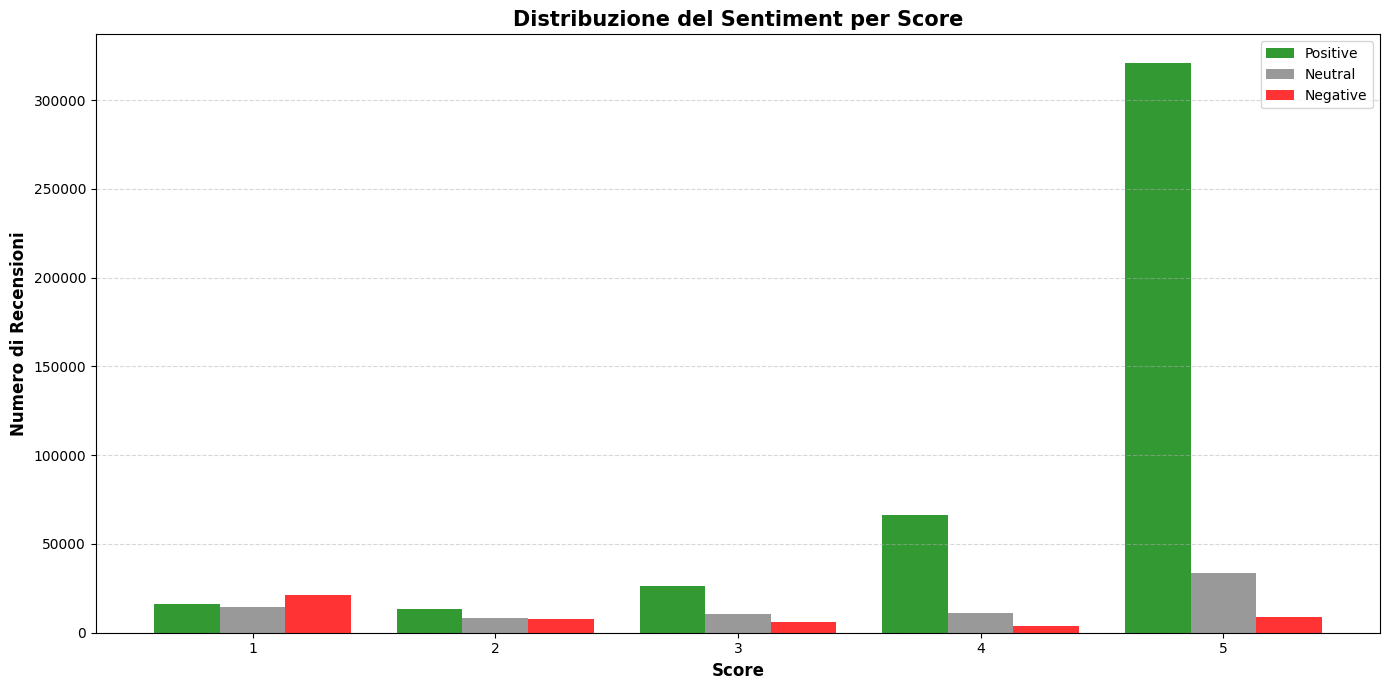

In [ ]:
# Query 4: Distribuzione del sentiment per score
sentiment_by_score = {}

for score in range(1, 6):
    col_name = f'score_{score}'
    pipeline = [
        {
            '$group': {
                '_id': '$sentiment',
                'count': {'$sum': 1}
            }
        }
    ]
    
    results = list(db[col_name].aggregate(pipeline))
    
    # Inizializza il dizionario per lo score
    sentiment_by_score[score] = {
        'positive': 0,
        'neutral': 0,
        'negative': 0
    }
    
    # Popola i conteggi
    for result in results:
        sentiment = result['_id']
        count = result['count']
        if sentiment in sentiment_by_score[score]:
            sentiment_by_score[score][sentiment] = count

print("Distribuzione del Sentiment per Score:\n")
print(f"{'Score':<8} {'Positive':<15} {'Neutral':<15} {'Negative':<15} {'Total':<10}")
print("-"*65)

for score in range(1, 6):
    pos = sentiment_by_score[score]['positive']
    neu = sentiment_by_score[score]['neutral']
    neg = sentiment_by_score[score]['negative']
    total = pos + neu + neg
    
    print(f"{score:<8} {pos:<15,} {neu:<15,} {neg:<15,} {total:<10,}")

print("-"*65)

# Visualizzazione con grafico a barre raggruppate
scores = list(range(1, 6))
positive_counts = [sentiment_by_score[s]['positive'] for s in scores]
neutral_counts = [sentiment_by_score[s]['neutral'] for s in scores]
negative_counts = [sentiment_by_score[s]['negative'] for s in scores]

x = np.arange(len(scores))
width = 0.27

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width, positive_counts, width, label='Positive', color='green', alpha=0.8)
bars2 = ax.bar(x, neutral_counts, width, label='Neutral', color='gray', alpha=0.8)
bars3 = ax.bar(x + width, negative_counts, width, label='Negative', color='red', alpha=0.8)

ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Numero di Recensioni', fontsize=12, fontweight='bold')
ax.set_title('Distribuzione del Sentiment per Score', fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(scores)
ax.legend()
ax.grid(axis='y', alpha=0.5, linestyle='--')

plt.tight_layout()
plt.show()

### Query 5: Prodotti con alto score medio (>=4.5) ma almeno 10% sentiment negativo

In [78]:
# Query 5: top prodotti
pipeline = [
    # unisce le 5 collezioni con score (escludiamo 'no_text')
    {"$unionWith": {"coll": "score_2"}},
    {"$unionWith": {"coll": "score_3"}},
    {"$unionWith": {"coll": "score_4"}},
    {"$unionWith": {"coll": "score_5"}},
    
    # raggruppa per prodotto e calcola le statistiche base
    {
        "$group": {
            "_id": "$product_id",
            "avg_score": {"$avg": "$score"},
            "total_reviews": {"$sum": 1},
            "negative_count": {
                "$sum": {
                    "$cond": [ {"$eq": ["$sentiment", "negative"]}, 1, 0 ]
                }
            },
            # Opzionale: aggiungiamo anche gli altri per un report completo
            "positive_count": {
                "$sum": {
                    "$cond": [ {"$eq": ["$sentiment", "positive"]}, 1, 0 ]
                }
            },
            "neutral_count": {
                "$sum": {
                    "$cond": [ {"$eq": ["$sentiment", "neutral"]}, 1, 0 ]
                }
            }
        }
    },
    
    # in questo caso rimuove tutto il "rumore" da 1 recensione
    {
        "$match": {
            "total_reviews": {"$gte": 10} # Minimo 10 recensioni
        }
    },

    # filtra per i due criteri richiesti
    # usa $expr per confrontare i campi calcolati
    {
        "$match": {
            "$expr": {
                "$and": [
                    # criterio 1: score medio >= 4.5
                    {"$gte": ["$avg_score", 4.5]},
                    
                    # criterio 2: % negativa >= 10% (0.10)
                    # calcola la percentuale al volo
                    {"$gte": [ 
                        {"$divide": ["$negative_count", "$total_reviews"]}, 
                        0.10 
                    ]}
                ]
            }
        }
    },
    
    # aggiunge il campo negative_pct per un output pulito
    {
        "$addFields": {
            "negative_pct": {
                "$multiply": [ 
                    {"$divide": ["$negative_count", "$total_reviews"]}, 
                    100 
                ]
            }
        }
    },

    # ordina per % negativa
    {"$sort": {"negative_pct": -1}}
]

print(f"Prodotti con Score Medio >= 4.5 e almeno 10% Sentiment Negativo:\n")

start_time = time.time()
# Eseguiamo l'unica query di aggregazione
try:
    # inizia da 'score_1' e unisce le altre
    qualifying_products = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
    elapsed = time.time() - start_time

    print(f"Trovati {len(qualifying_products)} prodotti (Tempo: {elapsed:.4f}s)")
    print("-"*60)

    if len(qualifying_products) > 0:
        print(f"{'Product ID':<20} {'Avg Score':>10} {'Reviews':>8} {'Neg':>6} {'Neg %':>8}")
        print("-"*60)

        for prod in qualifying_products[:20]: # mostra i primi 20
            print(f"{prod['_id']:<20} "
                    f"{prod['avg_score']:>10.2f} "
                    f"{prod['total_reviews']:>8} "
                    f"{prod['negative_count']:>6} "
                    f"{prod['negative_pct']:>7.1f}%")
    else:
        print("Nessun prodotto soddisfa i criteri specificati.")

except Exception as e:
    print(f"Errore durante l'aggregazione: {e}")

Prodotti con Score Medio >= 4.5 e almeno 10% Sentiment Negativo:

Trovati 464 prodotti (Tempo: 0.5685s)
------------------------------------------------------------
Product ID            Avg Score  Reviews    Neg    Neg %
------------------------------------------------------------
B000FBMFDO                 4.62       97     57    58.8%
B000EPOBYC                 4.54       13      4    30.8%
B0009F3QLQ                 4.62       50     15    30.0%
B000WAC1F0                 4.50       10      3    30.0%
B001JU7YJA                 4.50       10      3    30.0%
B000WAFJ0E                 4.50       10      3    30.0%
B0029J6JI2                 4.70       10      3    30.0%
B000EF3E3Q                 4.60       10      3    30.0%
B0014ET1S8                 4.50       14      4    28.6%
B001EQ4VXG                 4.91       11      3    27.3%
B001OCBSS6                 4.64       11      3    27.3%
B002UZSO2O                 4.73       11      3    27.3%
B0000DG56P                 4.55  

In [80]:
print("--- Analisi Anomalie: Score 5 Stelle con Sentiment Negativo ---")

# Definiamo la pipeline
# Cerchiamo solo nella collezione 'score_5' i documenti
# che VADER (con le tue soglie) ha classificato come 'negative'.
pipeline = [
    # 1. Filtra solo per sentiment negativo
    {
        "$match": {
            "sentiment": "negative"
        }
    },
    # 2. Mostra solo i campi rilevanti per l'analisi
    {
        "$project": {
            "_id": 0, # Nascondi l'ID
            "product_id": 1,
            "summary": 1,
            "text": 1,
            "sentiment": 1, # Dovrebbe essere sempre "negative"
            "score": 1      # Dovrebbe essere sempre 5
        }
    },
    # 3. Prendiamo solo i primi 20 esempi
    {
        "$limit": 20
    }
]

start_time = time.time()
try:
    # Eseguiamo la query SOLO sulla collezione score_5
    anomalies = list(db.score_5.aggregate(pipeline))
    elapsed = time.time() - start_time
    
    print(f"\nTrovate {len(anomalies)} recensioni anomale (Tempo: {elapsed:.4f}s)")
    print("Saranno visualizzati i testi per l'analisi manuale:\n")
    print("=" * 80)

    if not anomalies:
        print("Nessuna recensione con Score 5 e Sentiment Negativo trovata.")
    
    for i, doc in enumerate(anomalies, 1):
        print(f"ANOMALIA #{i}")
        print(f"Prodotto:   {doc.get('product_id')}")
        print(f"Score:      {doc.get('score')}")
        print(f"Sentiment:  {doc.get('sentiment')}")
        print(f"Summary:    {doc.get('summary')}")
        print(f"Text:       {doc.get('text')}")
        print("-" * 80)

except Exception as e:
    print(f"Errore durante l'aggregazione: {e}")

--- Analisi Anomalie: Score 5 Stelle con Sentiment Negativo ---

Trovate 20 recensioni anomale (Tempo: 0.0177s)
Saranno visualizzati i testi per l'analisi manuale:

ANOMALIA #1
Prodotto:   B0009XLVG0
Score:      5
Sentiment:  negative
Summary:    My cats LOVE this "diet" food better than their regular food
Text:       One of my boys needed to lose some weight and the other didn't.  I put this food on the floor for the chubby guy, and the protein-rich, no by-product food up higher where only my skinny boy can jump.  The higher food sits going stale.  They both really go for this food.  And my chubby boy has been losing about an ounce a week.
--------------------------------------------------------------------------------
ANOMALIA #2
Prodotto:   B000E7VI7S
Score:      5
Sentiment:  negative
Summary:    pretzel haven!
Text:       this was sooooo deliscious but too bad i ate em too fast and gained 2 pds! my fault
-----------------------------------------------------------------------------

### Discussione: Collezioni Multiple vs Collezione Unica

**Analisi della scelta di suddividere i dati in collezioni separate per score:**

#### a) Complessità delle Query
- **Collezioni Multiple (approccio corrente):**
  - ✗ Richiede query su più collezioni e aggregazione manuale dei risultati
  - ✗ Codice più complesso per query che coinvolgono tutti gli score
  - ✗ Necessità di iterare su 5-6 collezioni diverse
  
- **Collezione Unica con Indici:**
  - ✓ Query più semplici e dirette usando operatori MongoDB
  - ✓ Una sola query aggregation pipeline
  - ✓ Codice più manutenibile e leggibile

#### b) Prestazioni e Risorse
- **Collezioni Multiple:**
  - ✓ Possibile parallelizzazione delle query su collezioni diverse
  - ✓ Filtering automatico per score (collezione = score)
  - ✗ Overhead di gestione di multiple connessioni
  - ✗ Maggior consumo di memoria per gestire risultati multipli
  
- **Collezione Unica con Indici:**
  - ✓ MongoDB può ottimizzare meglio le query con indici su score
  - ✓ Uso efficiente della cache MongoDB
  - ✓ Minor overhead di gestione
  - ✗ Collezione più grande (ma compensato da indici efficienti)

#### c) Manutenibilità e Scalabilità
- **Collezioni Multiple:**
  - ✗ Difficile manutenzione (schemi duplicati)
  - ✗ Complessità nel gestire modifiche alla struttura
  - ✗ Backup e restore più complessi
  - ✓ Possibile sharding naturale per score
  
- **Collezione Unica con Indici:**
  - ✓ Schema unico, più facile da gestire
  - ✓ Operazioni di manutenzione semplificate
  - ✓ Backup e restore più semplici
  - ✓ Sharding flessibile su diversi campi

#### Conclusioni e Raccomandazioni

**Quando usare Collezioni Multiple:**
1. Partizionamento logico naturale (es. dati storici per anno)
2. Necessità di archiviazione distribuita fisica
3. Requisiti di retention diversi (es. score_1 conservato meno tempo)
4. Parallelizzazione hardware di query indipendenti

**Quando usare Collezione Unica (RACCOMANDATO per questo caso):**
1. Query che aggregano dati cross-score (come le nostre)
2. Schema uniforme tra le partizioni
3. Necessità di semplicità e manutenibilità
4. Uso di indici composti: `{score: 1, product_id: 1, sentiment: 1}`

**Struttura raccomandata:**
```javascript
db.reviews.createIndex({score: 1})
db.reviews.createIndex({product_id: 1})
db.reviews.createIndex({sentiment: 1})
db.reviews.createIndex({product_id: 1, score: 1})
db.reviews.createIndex({score: 1, sentiment: 1})
```

Questa soluzione offre:
- Performance eccellenti per le query analitiche
- Codice più semplice e manutenibile
- Flessibilità per query future
- Scalabilità attraverso sharding intelligente

# VERSIONE ALTERNATIVA

### Discussione sull'Architettura del Database (Task 3g)

La scelta (richiesta dall'esercizio) di suddividere le recensioni in sei collezioni distinte (`score_1`...`score_5` e `no_text`) si è rivelata un **ostacolo fondamentale** per lo svolgimento delle interrogazioni analitiche. Se da un lato questa struttura semplifica l'isolamento dei dati per un singolo score, dall'altro complica enormemente qualsiasi query che richieda una visione d'insieme, come abbiamo sperimentato.

---

### a) Impatto sulla Complessità delle Query

La suddivisione ha aumentato drasticamente la complessità di quasi tutte le query analitiche.

* **Query Semplici (Query 1 e 4):** Per rispondere a domande come "quanti documenti per score" o "distribuzione sentiment per score", siamo stati costretti a implementare la logica in Python. Abbiamo dovuto eseguire **5 query di aggregazione separate** (una per collezione) e poi unire i risultati manualmente nel nostro script.
* **Query Complesse (Query 2, 3 e 5):** Per le query che dovevano analizzare *tutti* i dati (top prodotti, top utenti, prodotti "controversi"), la complessità è esplosa. L'unica soluzione performante lato database è stata l'uso dell'operatore **`$unionWith`**. Questo ha reso le pipeline di aggregazione macchinose, richiedendo 4-5 stage di unione *prima* di poter iniziare la vera logica analitica (`$group`, `$match`).

Se avessimo avuto una collezione unica, ogni singola query (dalla 1 alla 5) sarebbe stata una singola pipeline di aggregazione, più semplice da scrivere, leggere e manutenere.

---

### b) Impatto su Prestazioni e Risorse

Le prestazioni sono state significativamente degradate da questa scelta, sia lato client che lato database.

* **Overhead delle Query:** L'esecuzione di 5 query separate (come per la Query 1 e 4) implica 5 round-trip di rete tra l'applicazione e il database, un overhead non necessario.
* **Overhead di `$unionWith`:** L'uso di `$unionWith` (Query 2, 3, 5) non è a costo zero. Obbliga MongoDB a gestire e unire 5-6 cursori/flussi di dati diversi prima di procedere. Questo è intrinsecamente più lento e richiede più CPU e RAM **lato server** rispetto a una singola aggregazione su una collezione unica.
* **L'unica Eccezione (Working Set):** L'unico, teorico, vantaggio si avrebbe se la stragrande maggioranza delle query fosse *esclusivamente* su un singolo score (es. "mostra solo recensioni a 5 stelle"). In quel caso, la collezione `score_5` più piccola potrebbe essere gestita più facilmente in RAM (il "working set") da MongoDB. Ma per un'applicazione analitica come questa, questo scenario è irrealistico.

---

### c) Impatto su Manutenibilità e Scalabilità

Questo è l'aspetto più problematico a lungo termine.

* **Manutenibilità:** L'approccio è quasi ingestibile.
    * **Schema:** Qualsiasi modifica allo schema (es. aggiungere un campo `is_verified`) deve essere replicata su **6 collezioni diverse**.
    * **Indici:** Ogni indice necessario (su `product_id`, `user_id`, `time`) deve essere creato e mantenuto su **6 collezioni**, moltiplicando l'uso dello spazio disco per gli indici e il costo (CPU/RAM) di ogni operazione di scrittura.
* **Scalabilità:** La scalabilità è *peggiore*.
    * **Sharding:** Tentare di fare "sharding" (distribuzione dei dati) basandosi sullo score sarebbe un disastro. Si creerebbe un **"hot shard"**, poiché la collezione `score_5` (con ~65% dei dati) riceverebbe la maggior parte del traffico, mentre lo shard `score_2` sarebbe quasi inutilizzato.
    * **Crescita:** Con la crescita del dataset, la gestione di decine di collezioni (se si decidesse di partizionare ulteriormente) diventerebbe impossibile.

---

### Confronto con una Collezione Unica Indicizzata

Una singola collezione `reviews` è la soluzione nettamente preferibile. La strategia corretta non è il partizionamento *fisico* (collezioni multiple), ma il partizionamento *logico* tramite **indici**.

Mantenendo tutti i ~568.000 documenti in un'unica collezione `reviews`, avremmo potuto creare pochi indici composti per ottimizzare *tutte* le nostre query:

```javascript
// Indice per le query 1, 4, 5 (filtro per score, poi sentiment)
db.reviews.createIndex({ score: 1, sentiment: 1 })

// Indice per le query 2, 3g (trova prodotto, poi media score/sentiment)
db.reviews.createIndex({ product_id: 1, score: 1 })

// Indice per la query 3 (trova top utenti)
db.reviews.createIndex({ user_id: 1 })

// Indice per il task 5 (analisi temporale per prodotto)
db.reviews.createIndex({ product_id: 1, time: 1 })
```

Con questa struttura:

1. Le query sarebbero più semplici (pipeline singole, senza $unionWith).

2. Le performance sarebbero massime, poiché il query planner di MongoDB potrebbe usare questi indici per accedere direttamente ai dati necessari, senza scansioni o unioni.

3. La manutenibilità sarebbe banale (uno schema, un set di indici).

---

#### Scenari d'Uso Corretti

Come richiesto, ci sono casi in cui la suddivisione in più collezioni è utile, ma il nostro non è uno di quelli.

Casi Utili per Collezioni Multiple:

1. Dati "Caldi" vs "Freddi": Separare i dati recenti (es. reviews_2025, su cui si fanno query frequenti) da quelli storici (es. reviews_archive_2010_2020, interrogati di rado).

2. Diverse Politiche di Retention (TTL): Avere collezioni separate per dati che scadono in tempi diversi (es. log_eventi_30giorni vs log_audit_7anni).

3. Isolamento del Working Set: Se i dati appartengono a "tenant" (clienti) diversi che non vengono mai aggregati tra loro (es. dati_cliente_A e dati_cliente_B).

4. Schema Davvero Diverso: Quando i documenti rappresentano entità diverse (es. users e products).

#### Casi Sbagliati per Collezioni Multiple (il nostro):

1. Dati con Schema Identico: Se i documenti hanno la stessa struttura.

2. Query Analitiche/Aggregative: Se hai bisogno di aggregare dati tra i diversi "silos".

3. Partizionamento su Campi a Bassa Cardinalità: Usare un campo come score (con solo 5-6 valori) come chiave di partizionamento fisico è un anti-pattern.

## 4. Sistema di Raccomandazione

Implementiamo un sistema ibrido che combina collaborative filtering e content-based filtering.

In [79]:
# usa uno dei prodotti con più recensioni (es. preso dalla Query 2 o 3)
TARGET_PRODUCT_ID = "B007PA32L2"
# TARGET_PRODUCT_ID = "B000KV61FC"

print(f"Avvio Raccomandazione per Prodotto: {TARGET_PRODUCT_ID}")

# Definiamo i pesi per il nostro sistema ibrido
W_COLLABORATIVE = 0.5  # 50% (Co-occorrenza)
W_CONTENT = 0.3        # 30% (Testo)
W_SENTIMENT = 0.2      # 20% (Qualità)

# Liste delle collezioni per le query
SCORE_COLLECTIONS = [f"score_{i}" for i in range(1, 6)]
# Collezioni per "recensito positivamente" (come da prompt)
POSITIVE_COLLECTIONS = ["score_4", "score_5"] 
# Pipeline di unione
UNION_PIPELINE_ALL = [{"$unionWith": {"coll": coll}} for coll in SCORE_COLLECTIONS[1:]]

# --- 1. Componente 1: Collaborative Filtering (Co-Occorrenza) ---
print("\n[1/4] Avvio Collaborative Filtering (Co-Occorrenza)...")
start_time = time.time()

# 1a. Troviamo gli utenti che hanno recensito POSITIVAMENTE il prodotto target
pipeline_users = [
    {"$match": {"product_id": TARGET_PRODUCT_ID}},
    {"$group": {"_id": "$user_id"}}
]
# Eseguiamo la query solo sulle collezioni positive
target_users = set()
union_positive = [{"$unionWith": {"coll": POSITIVE_COLLECTIONS[1]}}]
results = list(db[POSITIVE_COLLECTIONS[0]].aggregate(union_positive + pipeline_users))
target_users_list = [doc['_id'] for doc in results]

if not target_users_list:
    print(f"Errore: Nessun utente ha recensito positivamente {TARGET_PRODUCT_ID}. Impossibile continuare.")
    exit()

print(f"Trovati {len(target_users_list)} utenti che hanno recensito positivamente {TARGET_PRODUCT_ID}.")

# 1b. Troviamo i prodotti candidati (altri prodotti recensiti da questi utenti)
pipeline_candidates = [
    {"$match": {
        "user_id": {"$in": target_users_list},
        "product_id": {"$ne": TARGET_PRODUCT_ID} # Escludiamo il prodotto target
    }},
    {"$group": {
        "_id": "$product_id",
        "collaborative_score": {"$sum": 1} # Punteggio = N. di co-occorrenze
    }},
    {"$sort": {"collaborative_score": -1}},
    {"$limit": 100} # Limitiamo l'analisi ai Top 100 candidati per efficienza
]

# Eseguiamo l'unione su TUTTE le collezioni di score
full_pipeline = UNION_PIPELINE_ALL + pipeline_candidates
candidates_result = list(db[SCORE_COLLECTIONS[0]].aggregate(full_pipeline, allowDiskUse=True))

if not candidates_result:
    print(f"Nessun candidato trovato. Impossibile continuare.")
    exit()

# Convertiamo in DataFrame per unire facilmente i dati
df_candidates = pd.DataFrame(candidates_result).set_index('_id')
df_candidates.index.name = "product_id"

print(f"Trovati {len(df_candidates)} prodotti candidati. Tempo: {time.time() - start_time:.2f}s")


# --- 2. Componente 2: Sentiment Score ---
print("\n[2/4] Calcolo Punteggi Sentiment...")
start_time = time.time()
candidate_list = df_candidates.index.tolist() # Lista dei 100 candidati

pipeline_sentiment = [
    {"$match": {"product_id": {"$in": candidate_list}}},
    {"$group": {
        "_id": "$product_id",
        "positive_reviews": {
            "$sum": {"$cond": [{"$eq": ["$sentiment", "positive"]}, 1, 0]}
        },
        "total_reviews": {"$sum": 1}
    }},
    {"$project": {
        # Calcola la % di sentiment positivi
        "sentiment_score": {
            "$cond": [
                {"$eq": ["$total_reviews", 0]}, 
                0, 
                {"$divide": ["$positive_reviews", "$total_reviews"]}
            ]
        }
    }}
]

full_pipeline_sent = UNION_PIPELINE_ALL + pipeline_sentiment
sentiment_results = list(db[SCORE_COLLECTIONS[0]].aggregate(full_pipeline_sent, allowDiskUse=True))

df_sentiment = pd.DataFrame(sentiment_results).set_index('_id')
df_candidates = df_candidates.join(df_sentiment, how='left').fillna(0) # Uniamo i dati

print(f"Punteggi sentiment calcolati. Tempo: {time.time() - start_time:.2f}s")


# --- 3. Componente 3: Content Similarity (TF-IDF) ---
print("\n[3/4] Calcolo Similarità Testuale (TF-IDF)...")
start_time = time.time()

def get_aggregated_text(product_id_list):
    """
    Funzione helper che usa MongoDB per aggregare tutto il testo 
    di una lista di prodotti in singole stringhe GIGANTI.
    Questa è la risposta corretta al problema delle N+1 query.
    """
    pipeline_text = [
        {"$match": {"product_id": {"$in": product_id_list}}},
        {"$group": {
            "_id": "$product_id",
            # Raccoglie tutto il testo (summary + text)
            "all_text": {"$push": {"$concat": ["$summary", " ", "$text"]}}
        }},
        {"$project": {
            # Concatena tutti i testi di un prodotto in una singola stringa
            "full_text": {
                "$reduce": {
                    "input": "$all_text",
                    "initialValue": "",
                    "in": {"$concat": ["$$value", " ", "$$this"]}
                }
            }
        }}
    ]
    full_pipeline_text = UNION_PIPELINE_ALL + pipeline_text
    results = list(db[SCORE_COLLECTIONS[0]].aggregate(full_pipeline_text, allowDiskUse=True))
    return {doc['_id']: doc['full_text'] for doc in results}

# Otteniamo i testi aggregati solo per i nostri candidati + il target
product_texts = get_aggregated_text(candidate_list + [TARGET_PRODUCT_ID])

if TARGET_PRODUCT_ID not in product_texts:
    print(f"Errore: Testo per il prodotto target {TARGET_PRODUCT_ID} non trovato.")
    exit()

# Creiamo il corpus per TF-IDF (Target + Candidati)
target_text = product_texts.get(TARGET_PRODUCT_ID, "")
corpus_ids = [TARGET_PRODUCT_ID] + candidate_list
corpus_texts = [product_texts.get(pid, "") for pid in corpus_ids]

# Eseguiamo TF-IDF
vectorizer = TfidfVectorizer(stop_words='english', max_df=0.7, min_df=3, max_features=1000)
tfidf_matrix = vectorizer.fit_transform(corpus_texts)

# Calcoliamo la similarità tra il target (riga 0) e tutti gli altri
cosine_sim = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix)

# Creiamo il DataFrame di similarità
df_similarity = pd.DataFrame({
    'product_id': corpus_ids[1:], # Escludiamo il target stesso
    'content_score': cosine_sim[0][1:]
}).set_index('product_id')

df_candidates = df_candidates.join(df_similarity, how='left').fillna(0) # Uniamo i dati

print(f"Similarità TF-IDF calcolata. Tempo: {time.time() - start_time:.2f}s")


# --- 4. Calcolo Punteggio Ibrido e Classifica ---
print("\n[4/4] Calcolo Punteggio Ibrido Finale...")

# Normalizziamo tutti i punteggi su una scala 0-1 (fondamentale!)
# I punteggi (collaborative, sentiment, content) hanno scale diverse
scaler = MinMaxScaler()
df_candidates[['collaborative_score', 'sentiment_score', 'content_score']] = \
    scaler.fit_transform(df_candidates[['collaborative_score', 'sentiment_score', 'content_score']])

# Calcoliamo il punteggio finale pesato
df_candidates['final_score'] = (
    W_COLLABORATIVE * df_candidates['collaborative_score'] +
    W_SENTIMENT * df_candidates['sentiment_score'] +
    W_CONTENT * df_candidates['content_score']
)

# Ordiniamo e mostriamo i Top 3
df_top_3 = df_candidates.sort_values(by='final_score', ascending=False).head(3)

print("\n--- TOP 3 PRODOTTI RACCOMANDATI ---")
print(f"Simili a: {TARGET_PRODUCT_ID}\n")
print(f"{'Product ID':<15} {'Score Finale':<12} {'(Collaborative)':<15} {'(Sentiment)':<12} {'(Content)':<10}")
print("-"*70)

for pid, row in df_top_3.iterrows():
    print(f"{pid:<15} "
            f"{row['final_score']:<12.4f} "
            f"{row['collaborative_score']:<15.4f} "
            f"{row['sentiment_score']:<12.4f} "
            f"{row['content_score']:<10.4f}")

Avvio Raccomandazione per Prodotto: B007PA32L2

[1/4] Avvio Collaborative Filtering (Co-Occorrenza)...
Trovati 179 utenti che hanno recensito positivamente B007PA32L2.
Trovati 100 prodotti candidati. Tempo: 0.21s

[2/4] Calcolo Punteggi Sentiment...
Punteggi sentiment calcolati. Tempo: 0.11s

[3/4] Calcolo Similarità Testuale (TF-IDF)...
Similarità TF-IDF calcolata. Tempo: 0.73s

[4/4] Calcolo Punteggio Ibrido Finale...

--- TOP 3 PRODOTTI RACCOMANDATI ---
Simili a: B007PA32L2

Product ID      Score Finale (Collaborative) (Sentiment)  (Content) 
----------------------------------------------------------------------
B003Z6ZGZU      0.8856       1.0000          0.4282       1.0000    
B004T3QMD8      0.4655       0.0056          0.9699       0.8955    
B001WRHQRA      0.4170       0.0000          0.6094       0.9837    


## Classificazione del Sistema di Raccomandazione

Questo è un "Sistema di Raccomandazione Ibrido" (Hybrid Recommender System).

Nello specifico, utilizza una strategia di weighted hybrid (ibrido pesato), che combina i punteggi di diversi modelli:

1. Collaborative Filtering (Filtro Collaborativo):

    * Metodo: "Co-occorrenza di utenti".

    * Perché: Raccomanda prodotti basandosi sul comportamento di utenti simili (quelli che hanno recensito gli stessi prodotti). Non guarda al contenuto del prodotto, ma solo alle interazioni utente-prodotto.

2. Content-Based Filtering (Filtro Basato sul Contenuto):

    * Metodo: "Somiglianza lessicale tra i testi" (TF-IDF).

    * Perché: Raccomanda prodotti analizzando le loro "caratteristiche" intrinseche (in questo caso, le parole usate nelle recensioni). Trova prodotti che sono oggettivamente simili al prodotto target.

3. Filtro di Qualità/Popolarità:

    * Metodo: "Media dei sentiment positivi".

    * Perché: Questo agisce come un filtro di qualità. Tra i prodotti simili, diamo un "bonus" a quelli che sono generalmente più apprezzati (alta percentuale di sentiment positivo), evitando di raccomandare prodotti che sono sì simili, ma pessimi.

## 5. Analisi Avanzata - Evoluzione del Sentiment nel Tempo

Analizziamo l'evoluzione temporale del sentiment per i top 5 prodotti.

In [46]:
# Recupera i top 5 prodotti (già calcolati precedentemente)
print("Top 5 prodotti per analisi temporale:")
for i, prod in enumerate(top_5_products, 1):
    print(f"{i}. {prod['_id']} (avg score: {prod['avg_score']:.2f})")

Top 5 prodotti per analisi temporale:
1. B000RL53PE (avg score: 5.00)
2. B005EL6VOY (avg score: 5.00)
3. B001IZ9ME6 (avg score: 5.00)
4. B00376ZEY6 (avg score: 5.00)
5. B0029O0XGQ (avg score: 5.00)


In [48]:
# Funzione per calcolare l'andamento mensile del sentiment
def analyze_temporal_sentiment(product_id):
    """
    Analizza l'evoluzione del sentiment nel tempo per un prodotto
    Restituisce un DataFrame con l'andamento mensile
    """
    reviews = []
    
    # Raccoglie tutte le recensioni del prodotto
    for col_name in [f'score_{i}' for i in range(1, 6)]:
        for doc in db[col_name].find({'product_id': product_id}):
            reviews.append({
                'time': doc['time'],
                'sentiment': doc.get('sentiment', 'neutral'),
                'score': doc['score']
            })
    
    # Crea DataFrame
    df_reviews = pd.DataFrame(reviews)
    
    if len(df_reviews) == 0:
        return None
    
    # Estrai anno-mese
    df_reviews['year_month'] = df_reviews['time'].dt.to_period('M')
    
    # Calcola proporzioni per ogni mese
    monthly_sentiment = df_reviews.groupby(['year_month', 'sentiment']).size().unstack(fill_value=0)
    
    # Calcola percentuali
    monthly_total = monthly_sentiment.sum(axis=1)
    monthly_pct = monthly_sentiment.div(monthly_total, axis=0) * 100
    
    # Assicurati che tutte le colonne esistano
    for sent in ['positive', 'neutral', 'negative']:
        if sent not in monthly_pct.columns:
            monthly_pct[sent] = 0
    
    return monthly_pct[['positive', 'neutral', 'negative']]

# Analizza i top 5 prodotti
temporal_data = {}

print("Raccolta dati temporali per i top 5 prodotti...")
for prod in top_5_products:
    pid = prod['_id']
    data = analyze_temporal_sentiment(pid)
    if data is not None and len(data) > 0:
        temporal_data[pid] = data
        print(f"✓ {pid}: {len(data)} mesi di dati")
    else:
        print(f"✗ {pid}: nessun dato disponibile")

Raccolta dati temporali per i top 5 prodotti...
✓ B000RL53PE: 22 mesi di dati
✓ B005EL6VOY: 12 mesi di dati
✓ B001IZ9ME6: 20 mesi di dati
✓ B00376ZEY6: 16 mesi di dati
✓ B0029O0XGQ: 16 mesi di dati


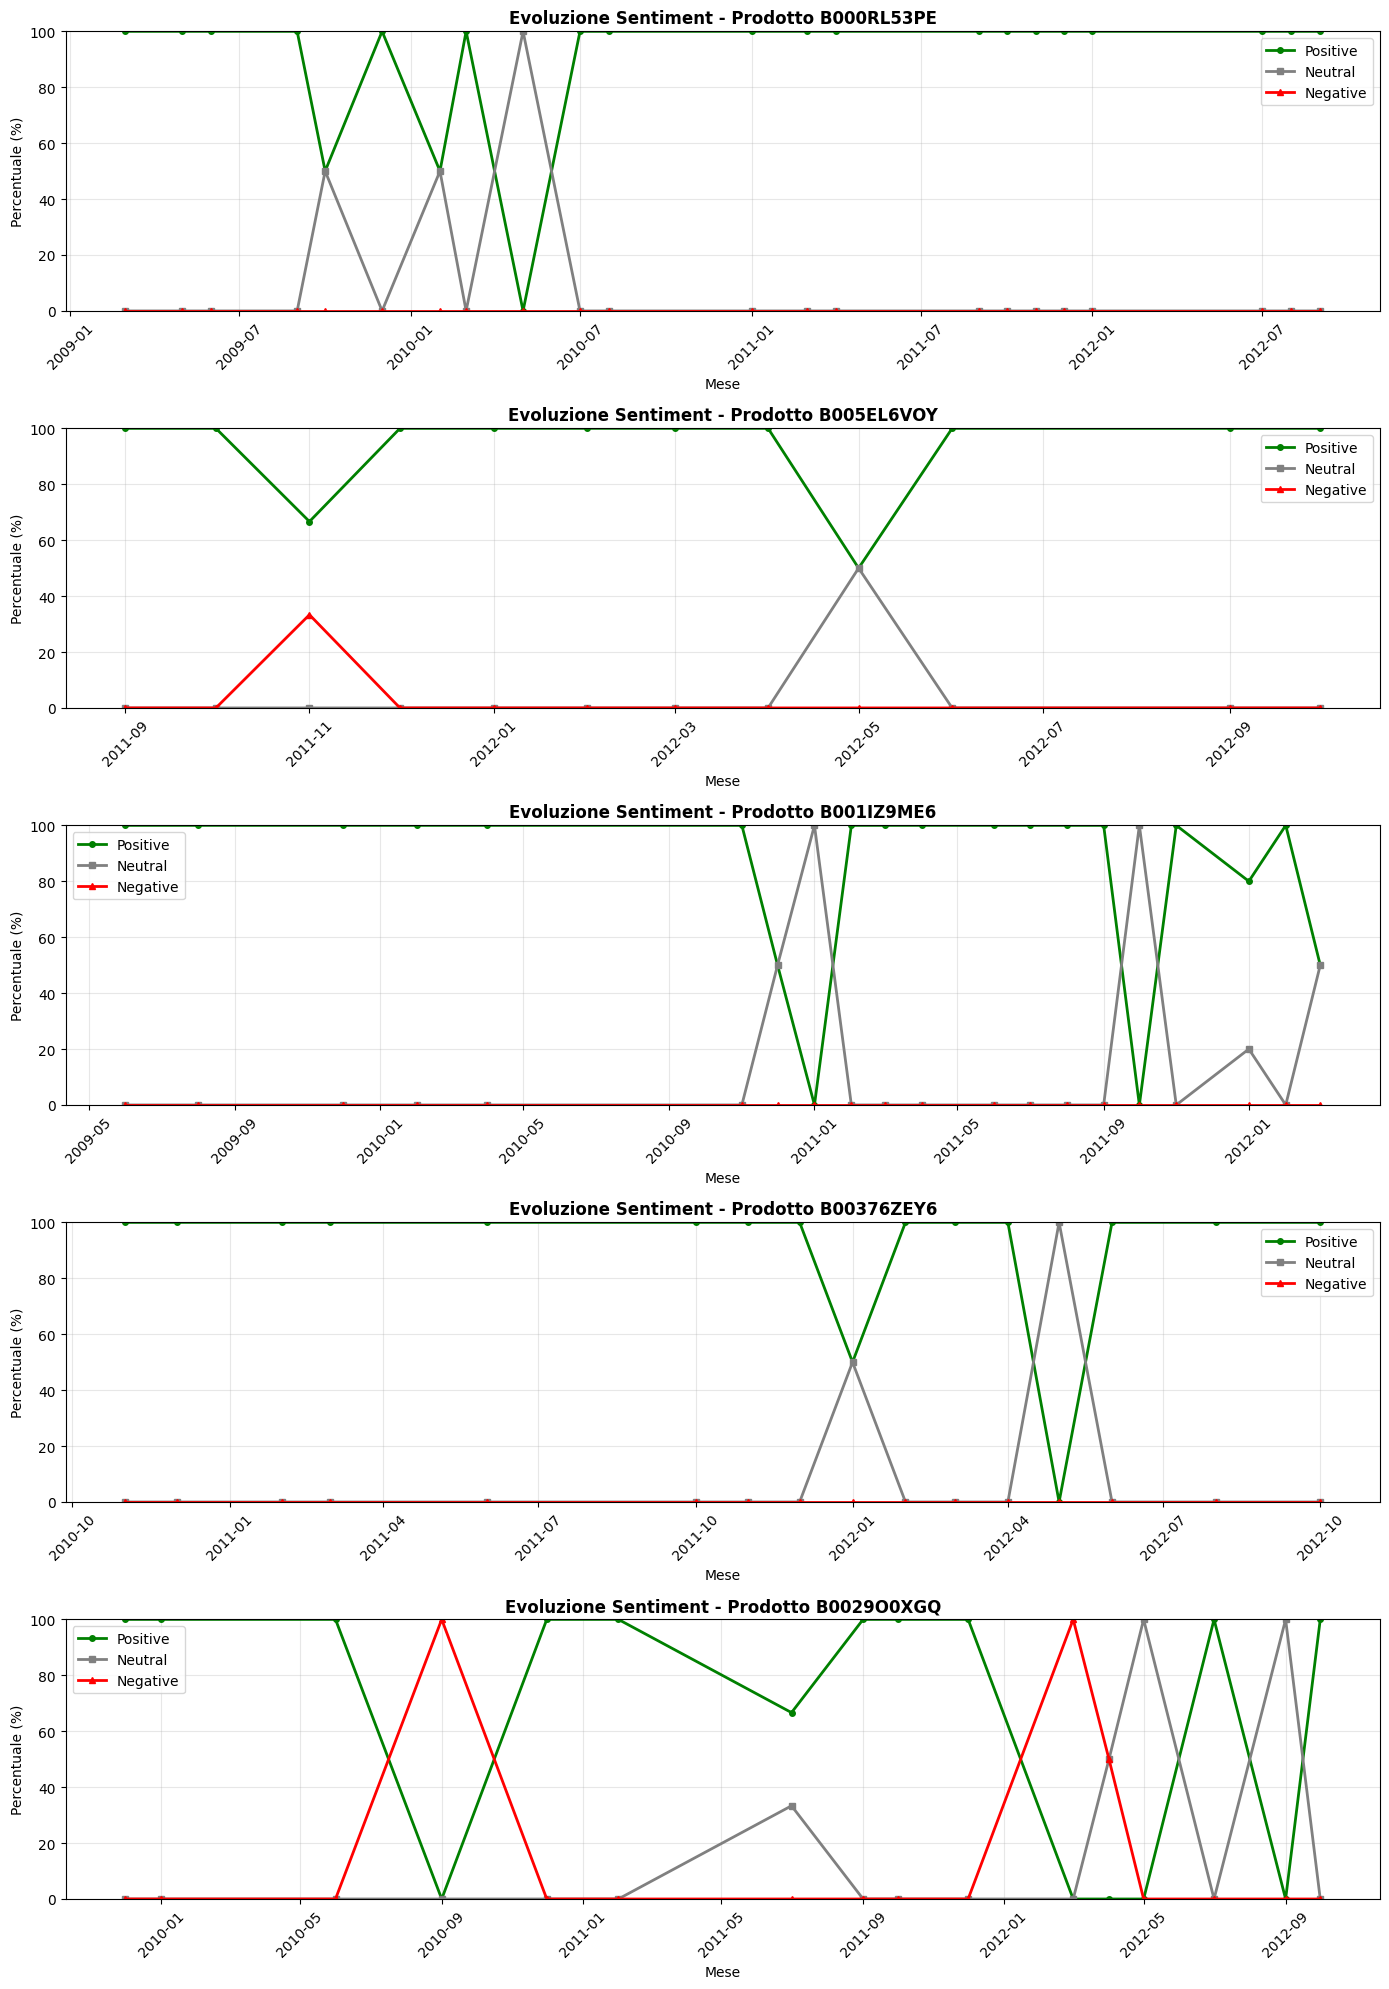


✓ Grafici generati per 5 prodotti


In [49]:
# Visualizzazione dell'evoluzione del sentiment
fig, axes = plt.subplots(len(temporal_data), 1, figsize=(14, 4 * len(temporal_data)))

if len(temporal_data) == 1:
    axes = [axes]

for idx, (product_id, data) in enumerate(temporal_data.items()):
    ax = axes[idx]
    
    # Converti period in datetime per plotting
    x_values = data.index.to_timestamp()
    
    # Plot delle tre linee
    ax.plot(x_values, data['positive'], 'g-o', label='Positive', linewidth=2, markersize=4)
    ax.plot(x_values, data['neutral'], color='gray', marker='s', label='Neutral', 
            linewidth=2, markersize=4)
    ax.plot(x_values, data['negative'], 'r-^', label='Negative', linewidth=2, markersize=4)
    
    ax.set_title(f'Evoluzione Sentiment - Prodotto {product_id}', 
                fontsize=12, fontweight='bold')
    ax.set_xlabel('Mese', fontsize=10)
    ax.set_ylabel('Percentuale (%)', fontsize=10)
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 100)
    
    # Formatta asse x
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f"\n✓ Grafici generati per {len(temporal_data)} prodotti")

### Identificazione Automatica delle Anomalie

In [ ]:
def detect_sentiment_anomalies(temporal_df, threshold=20):
    """
    Identifica anomalie/cambiamenti significativi nel sentiment
    
    Parameters:
    - temporal_df: DataFrame con l'andamento mensile del sentiment
    - threshold: soglia percentuale per considerare un cambiamento significativo
    
    Returns:
    - Lista di anomalie rilevate
    """
    anomalies = []
    
    # Calcola le variazioni month-over-month
    for sentiment_type in ['positive', 'neutral', 'negative']:
        if sentiment_type in temporal_df.columns:
            # Calcola la differenza percentuale rispetto al mese precedente
            diff = temporal_df[sentiment_type].diff()
            
            # Identifica variazioni superiori alla soglia
            significant_changes = diff[abs(diff) > threshold]
            
            for period, change in significant_changes.items():
                anomalies.append({
                    'period': str(period),
                    'sentiment_type': sentiment_type,
                    'change': change,
                    'previous_value': temporal_df.loc[period, sentiment_type] - change,
                    'current_value': temporal_df.loc[period, sentiment_type]
                })
    
    return anomalies

# Analizza anomalie per ogni prodotto
print("RILEVAMENTO ANOMALIE NEL SENTIMENT")
print("="*90)
print(f"Soglia: variazioni > 20% rispetto al mese precedente\n")

all_anomalies = {}

for product_id, data in temporal_data.items():
    anomalies = detect_sentiment_anomalies(data, threshold=20)
    all_anomalies[product_id] = anomalies
    
    if anomalies:
        print(f"\nProdotto: {product_id}")
        print(f"   Trovate {len(anomalies)} anomalie:")
        print("-"*90)
        
        for anom in anomalies:
            direction = "↑" if anom['change'] > 0 else "↓"
            print(f"   {anom['period']}: {anom['sentiment_type'].upper()} {direction} "
                f"{abs(anom['change']):.1f}% "
                f"({anom['previous_value']:.1f}% → {anom['current_value']:.1f}%)")
    else:
        print(f"\n✓ Prodotto: {product_id}")
        print(f"   Nessuna anomalia rilevata (andamento stabile)")

print("\n" + "="*90)

RILEVAMENTO ANOMALIE NEL SENTIMENT
Soglia: variazioni > 20% rispetto al mese precedente


Prodotto: B000RL53PE
   Trovate 12 anomalie:
------------------------------------------------------------------------------------------
   2009-10: POSITIVE ↓ 50.0% (100.0% → 50.0%)
   2009-12: POSITIVE ↑ 50.0% (50.0% → 100.0%)
   2010-02: POSITIVE ↓ 50.0% (100.0% → 50.0%)
   2010-03: POSITIVE ↑ 50.0% (50.0% → 100.0%)
   2010-05: POSITIVE ↓ 100.0% (100.0% → 0.0%)
   2010-07: POSITIVE ↑ 100.0% (0.0% → 100.0%)
   2009-10: NEUTRAL ↑ 50.0% (0.0% → 50.0%)
   2009-12: NEUTRAL ↓ 50.0% (50.0% → 0.0%)
   2010-02: NEUTRAL ↑ 50.0% (0.0% → 50.0%)
   2010-03: NEUTRAL ↓ 50.0% (50.0% → 0.0%)
   2010-05: NEUTRAL ↑ 100.0% (0.0% → 100.0%)
   2010-07: NEUTRAL ↓ 100.0% (100.0% → 0.0%)

Prodotto: B005EL6VOY
   Trovate 8 anomalie:
------------------------------------------------------------------------------------------
   2011-11: POSITIVE ↓ 33.3% (100.0% → 66.7%)
   2011-12: POSITIVE ↑ 33.3% (66.7% → 100.0%)
   2012-

### Discussione: Cause delle Variazioni e Adattamento del Sistema di Raccomandazione

#### Possibili Cause delle Variazioni di Sentiment

1. **Cambiamenti nella Qualità del Prodotto**
   - Modifiche nella ricetta o ingredienti
   - Cambiamenti nel processo produttivo
   - Problemi di controllo qualità

2. **Problemi nella Supply Chain**
   - Prodotti danneggiati durante la spedizione
   - Problemi di conservazione/scadenza
   - Cambiamenti nel packaging

3. **Aspettative dei Consumatori**
   - Aumento delle aspettative nel tempo
   - Disponibilità di alternative migliori
   - Cambiamenti nelle preferenze alimentari

4. **Fattori Stagionali**
   - Variazioni stagionali nella domanda
   - Disponibilità di ingredienti
   - Effetti climatici sulla conservazione

5. **Bias nel Campionamento**
   - Campagne promozionali che attraggono nuovi clienti
   - Recensioni incentivate
   - Trend virali (positivi o negativi)

#### Adattamento del Sistema di Raccomandazione

Il sistema di raccomandazione può adattarsi alle variazioni temporali in diversi modi:

##### 1. **Time Decay Factor**
```python
# Assegnare peso maggiore alle recensioni recenti
time_weight = exp(-lambda * (current_date - review_date))
weighted_sentiment = sentiment_score * time_weight
```

##### 2. **Trending Score**
```python
# Identificare prodotti con trend negativo recente
recent_sentiment_avg = avg(sentiment_last_3_months)
overall_sentiment_avg = avg(sentiment_all_time)

if recent_sentiment_avg < overall_sentiment_avg - threshold:
    # Ridurre score di raccomandazione
    recommendation_score *= 0.5
```

##### 3. **Anomaly Penalty**
```python
# Penalizzare prodotti con anomalie negative recenti
if has_recent_negative_anomaly(product_id):
    recommendation_score *= 0.7
```

##### 4. **Strategie di Adattamento Implementabili**

**a) Window-Based Filtering**
- Considerare solo recensioni degli ultimi N mesi (es. 6 mesi)
- Vantaggi: risposta rapida ai cambiamenti
- Svantaggi: meno dati per prodotti con poche recensioni

**b) Exponential Moving Average**
- Applicare pesi decrescenti alle recensioni più vecchie
- Vantaggi: bilanciamento tra storia e trend recenti
- Svantaggi: complessità computazionale

**c) Multi-Horizon Recommendation**
- Mantenere score separati per breve/medio/lungo termine
- Combinare in base al contesto dell'utente
- Vantaggi: flessibilità e robustezza
- Svantaggi: overhead computazionale

**d) Volatility Score**
- Calcolare la volatilità del sentiment nel tempo
- Penalizzare prodotti con alta volatilità
- Formula: `volatility = std(monthly_sentiment_changes)`

##### 5. **Implementazione Pratica**

```python
def adaptive_recommendation_score(product_id):
    # Score base (sistema attuale)
    base_score = collaborative_filtering_score + 
                 content_based_score + 
                 sentiment_score
    
    # Fattore temporale (ultimi 3 mesi vs tutti)
    recent_sentiment = get_sentiment_last_n_months(product_id, 3)
    all_time_sentiment = get_all_time_sentiment(product_id)
    
    trend_factor = 1.0
    if recent_sentiment < all_time_sentiment - 0.15:
        trend_factor = 0.6  # Penalità per trend negativo
    elif recent_sentiment > all_time_sentiment + 0.15:
        trend_factor = 1.2  # Boost per trend positivo
    
    # Controllo anomalie
    anomaly_penalty = 1.0
    if has_negative_anomaly_last_n_months(product_id, 2):
        anomaly_penalty = 0.5
    
    # Score finale adattivo
    return base_score * trend_factor * anomaly_penalty
```

#### Conclusioni

L'integrazione dell'analisi temporale nel sistema di raccomandazione permette di:
- **Proteggere gli utenti** da prodotti in declino qualitativo
- **Valorizzare prodotti** con trend positivi emergenti
- **Aumentare la fiducia** nel sistema attraverso raccomandazioni aggiornate
- **Migliorare le metriche** di business (soddisfazione, retention, conversioni)

La chiave è trovare il giusto bilanciamento tra:
- **Reattività** ai cambiamenti (non raccomandare prodotti problematici)
- **Stabilità** delle raccomandazioni (evitare fluttuazioni eccessive)
- **Robustezza** ai bias temporanei (es. campagne promozionali)

In [52]:
# --- 5a: Calcolo Andamento Mensile (Versione Ottimizzata) ---

def analyze_temporal_sentiment_mongodb(product_id):
    """
    Analizza l'evoluzione del sentiment usando una singola pipeline
    di aggregazione MongoDB per prodotto.
    """
    
    # Pipeline per unire, raggruppare per (anno, mese) e per (sentiment)
    pipeline = [
        # 1. Unisci le 5 collezioni di score
        {"$unionWith": {"coll": "score_2"}},
        {"$unionWith": {"coll": "score_3"}},
        {"$unionWith": {"coll": "score_4"}},
        {"$unionWith": {"coll": "score_5"}},
        
        # 2. Filtra solo per il prodotto target
        {"$match": {"product_id": product_id}},
        
        # 3. Raggruppa per Mese E per Sentiment
        {
            "$group": {
                "_id": {
                    # Tronca la data all'inizio del mese
                    "year_month": {
                        "$dateTrunc": {
                            "date": "$time", "unit": "month"
                        }
                    },
                    "sentiment": "$sentiment"
                },
                "count": {"$sum": 1}
            }
        },
        
        # 4. Fase "Pivot": Raggruppa solo per mese
        {
            "$group": {
                "_id": "$_id.year_month", # Ora raggruppiamo solo per mese
                "positive": {
                    "$sum": {"$cond": [ {"$eq": ["$_id.sentiment", "positive"]}, "$count", 0 ]}
                },
                "neutral": {
                    "$sum": {"$cond": [ {"$eq": ["$_id.sentiment", "neutral"]}, "$count", 0 ]}
                },
                "negative": {
                    "$sum": {"$cond": [ {"$eq": ["$_id.sentiment", "negative"]}, "$count", 0 ]}
                }
            }
        },
        
        # 5. Calcola Totale e Percentuali
        {
            "$project": {
                "total": {"$add": ["$positive", "$neutral", "$negative"]},
                "positive_pct": {
                    "$multiply": [
                        {"$cond": [
                            {"$eq": [{"$add": ["$positive", "$neutral", "$negative"]}, 0]},
                            0,
                            {"$divide": ["$positive", {"$add": ["$positive", "$neutral", "$negative"]}]}
                        ]},
                        100
                    ]
                },
                "neutral_pct": {
                    "$multiply": [
                        {"$cond": [
                            {"$eq": [{"$add": ["$positive", "$neutral", "$negative"]}, 0]},
                            0,
                            {"$divide": ["$neutral", {"$add": ["$positive", "$neutral", "$negative"]}]}
                        ]},
                        100
                    ]
                },
                "negative_pct": {
                    "$multiply": [
                        {"$cond": [
                            {"$eq": [{"$add": ["$positive", "$neutral", "$negative"]}, 0]},
                            0,
                            {"$divide": ["$negative", {"$add": ["$positive", "$neutral", "$negative"]}]}
                        ]},
                        100
                    ]
                }
            }
        },
        
        # 6. Ordina cronologicamente
        {"$sort": {"_id": 1}}
    ]
    
    # Esegui l'aggregazione
    try:
        results = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
    except Exception as e:
        print(f"Errore aggregazione per {product_id}: {e}")
        return None
        
    if not results:
        return None
        
    # Converti in DataFrame (molto più leggero, solo dati mensili)
    df = pd.DataFrame.from_records(results)
    
    # Rinomina la colonna data e impostala come indice
    df.rename(columns={'_id': 'month'}, inplace=True)
    df.set_index('month', inplace=True)
    
    # Assicurati che le colonne esistano (per il plot)
    for sent in ['positive_pct', 'neutral_pct', 'negative_pct']:
        if sent not in df.columns:
            df[sent] = 0.0
            
    return df[['positive_pct', 'neutral_pct', 'negative_pct']]

# --- Esegui Analisi ---
temporal_data = {}
print("Raccolta dati temporali per i top 5 prodotti (MongoDB Aggregation)...")

for prod in top_5_products:
    pid = prod['_id']
    data = analyze_temporal_sentiment_mongodb(pid)
    if data is not None and not data.empty:
        temporal_data[pid] = data
        print(f"✓ {pid}: {len(data)} mesi di dati")
    else:
        print(f"✗ {pid}: nessun dato disponibile")

Raccolta dati temporali per i top 5 prodotti (MongoDB Aggregation)...
✓ B000RL53PE: 22 mesi di dati
✓ B005EL6VOY: 12 mesi di dati
✓ B001IZ9ME6: 20 mesi di dati
✓ B00376ZEY6: 16 mesi di dati
✓ B0029O0XGQ: 16 mesi di dati



Generazione grafici per 5 prodotti...


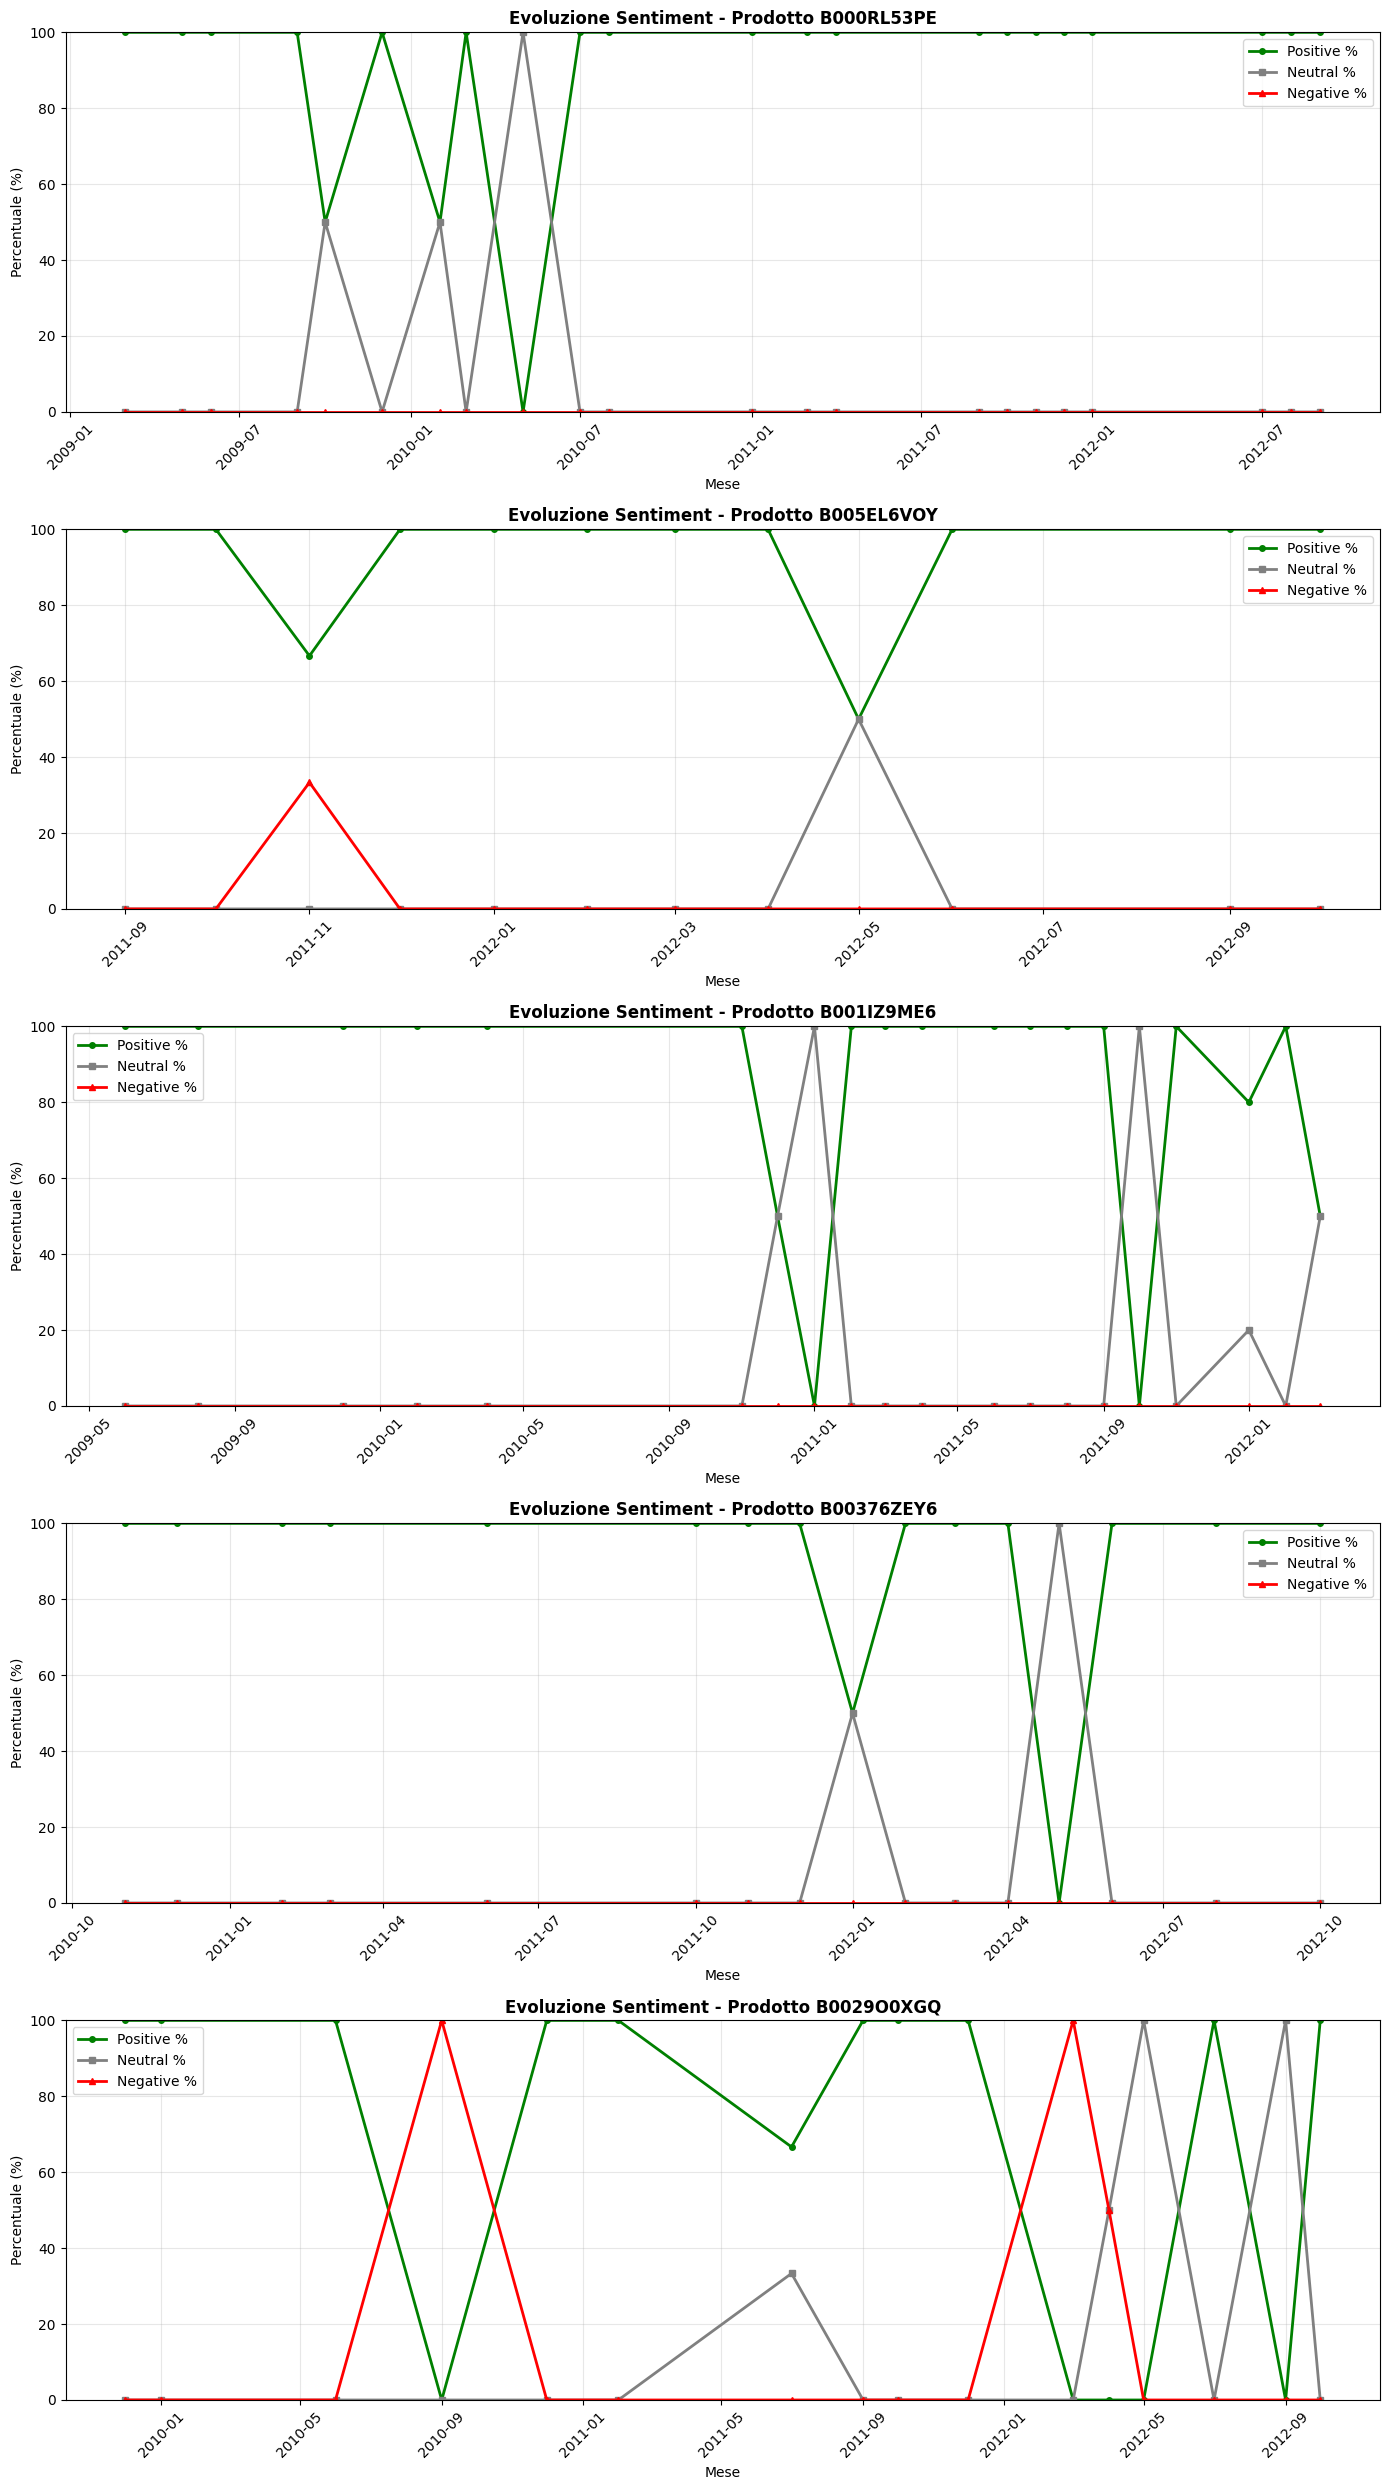

In [53]:
# --- 5b: Visualizzazione ---
print(f"\nGenerazione grafici per {len(temporal_data)} prodotti...")
fig, axes = plt.subplots(len(temporal_data), 1, 
                        figsize=(14, 5 * len(temporal_data)), 
                        squeeze=False)

for idx, (product_id, data) in enumerate(temporal_data.items()):
    ax = axes[idx, 0] # axes è 2D
    
    # Plot delle tre linee
    ax.plot(data.index, data['positive_pct'], 'g-o', label='Positive %', linewidth=2, markersize=4)
    ax.plot(data.index, data['neutral_pct'], color='gray', marker='s', label='Neutral %', linewidth=2, markersize=4)
    ax.plot(data.index, data['negative_pct'], 'r-^', label='Negative %', linewidth=2, markersize=4)
    
    ax.set_title(f'Evoluzione Sentiment - Prodotto {product_id}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Mese', fontsize=10)
    ax.set_ylabel('Percentuale (%)', fontsize=10)
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 100)
    
    # Formatta asse x
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [54]:
# --- 5c: Identificazione Anomalie ---
print("\n--- Task 5c: Rilevamento Anomalie (Aumento Negativo > 20%) ---")

def find_sentiment_anomalies(df_monthly, product_id):
    """
    Identifica picchi di sentiment negativo usando Pandas .diff()
    """
    anomalies_found = 0
    
    # Calcola la differenza (aumento) rispetto al mese precedente
    df_monthly['negative_change'] = df_monthly['negative_pct'].diff()
    
    # Filtra per anomalie (aumento > 20%)
    anomalies = df_monthly[df_monthly['negative_change'] > 20]
    
    if anomalies.empty:
        print(f"[{product_id}]: Nessuna anomalia significativa trovata.")
        return

    print(f"[{product_id}]: RILEVATE {len(anomalies)} ANOMALIE!")
    for date, row in anomalies.iterrows():
        print(f"  - {date.strftime('%Y-%m')}: Sentiment negativo aumentato a {row['negative_pct']:.1f}%")
        print(f"    (Aumento di +{row['negative_change']:.1f}% rispetto al mese precedente)")

# Esegui il rilevatore di anomalie per ogni prodotto
for product_id, data in temporal_data.items():
    find_sentiment_anomalies(data, product_id)


--- Task 5c: Rilevamento Anomalie (Aumento Negativo > 20%) ---
[B000RL53PE]: Nessuna anomalia significativa trovata.
[B005EL6VOY]: RILEVATE 1 ANOMALIE!
  - 2011-11: Sentiment negativo aumentato a 33.3%
    (Aumento di +33.3% rispetto al mese precedente)
[B001IZ9ME6]: Nessuna anomalia significativa trovata.
[B00376ZEY6]: Nessuna anomalia significativa trovata.
[B0029O0XGQ]: RILEVATE 2 ANOMALIE!
  - 2010-09: Sentiment negativo aumentato a 100.0%
    (Aumento di +100.0% rispetto al mese precedente)
  - 2012-03: Sentiment negativo aumentato a 100.0%
    (Aumento di +100.0% rispetto al mese precedente)


### 5d. Discussione: Cause delle Variazioni e Adattamento del Recommender

Il rilevamento di anomalie (Task 5c) non è un semplice esercizio tecnico; è una funzionalità di business intelligence cruciale. Un improvviso aumento del sentiment negativo è un segnale d'allarme che un prodotto sta avendo problemi adesso.

Possibili Cause di Variazioni Negative Improvvise

Un picco negativo raramente è casuale. Di solito è legato a un evento specifico:

1. Modifica del Prodotto: Il caso più comune. L'azienda ha cambiato la "nuova formula", ha usato ingredienti più economici o ha ridotto la quantità (es. "shrinkflation"), deludendo i clienti abituali.

2. Problemi di Packaging/Logistica: Un lotto di produzione spedito con imballaggi difettosi che portano a prodotti rotti, sciolti o avariati.

3. Variazione di Prezzo: Un improvviso e ingiustificato aumento di prezzo.

4. Lotto Difettoso: Un lotto specifico di produzione con problemi di qualità (sapore, odore) che viene distribuito nello stesso periodo.

5. Evento Esterno: Molto raro per il cibo, ma potrebbe essere una notizia (es. un richiamo sanitario) che spaventa i consumatori.

Come un Sistema di Raccomandazione Dovrebbe Adattarsi

Un sistema di raccomandazione che si basa su una media storica (come il nostro "Top 5 Prodotti" della Query 2) è pericoloso. Potrebbe continuare a promuovere attivamente un prodotto che, nelle ultime 3 settimane, è diventato pessimo e sta generando clienti furiosi.

Per questo, un sistema robusto deve adattarsi:

1. Introdurre un Decadimento Temporale (Time Decay): Le recensioni recenti devono pesare molto di più di quelle di 5 anni fa. Invece di una media semplice ($avg), si usa una media ponderata dove il peso della recensione diminuisce con il tempo.

2. Basare il Punteggio di Qualità su Dati Recenti: Il "punteggio sentiment" (Componente 2) del nostro sistema ibrido non dovrebbe essere calcolato su tutte le recensioni, ma solo su quelle degli ultimi 3-6 mesi.

3. Implementare un "Circuit Breaker" (Interruttore): Questa è la contromisura più importante. Il nostro script di rilevamento anomalie (Task 5c) dovrebbe girare automaticamente (es. ogni notte). Se rileva un'anomalia (es. sentiment negativo > 20% negli ultimi 30 giorni), deve escludere automaticamente quel prodotto da tutte le raccomandazioni, indipendentemente dal suo punteggio storico, finché non viene revisionato manualmente.

## Statistiche Finali del Database

In [55]:
# Statistiche complete del database MongoDB
print("="*80)
print("STATISTICHE FINALI DATABASE MONGODB")
print("="*80)

# Statistiche per collezione
print("\n1 - STATISTICHE PER COLLEZIONE:")
print("-"*80)
collection_stats = {}

for col_name in [f'score_{i}' for i in range(1, 6)] + ['no_text']:
    collection = db[col_name]
    
    # Conta documenti
    doc_count = collection.count_documents({})
    collection_stats[col_name] = {
        'count': doc_count,
        'avg_docs': {}
    }
    
    # Dimensione stimata (in bytes)
    stats = db.command("collStats", col_name)
    size_mb = stats.get('size', 0) / (1024 * 1024)
    collection_stats[col_name]['size_mb'] = size_mb
    
    print(f"{col_name:15s}: {doc_count:7,d} docs | {size_mb:8.2f} MB")

print("-"*80)
total_docs = sum(s['count'] for s in collection_stats.values())
total_size = sum(s['size_mb'] for s in collection_stats.values())
print(f"{'TOTALE':15s}: {total_docs:7,d} docs | {total_size:8.2f} MB")

# Statistiche sentiment
print("\n2 - DISTRIBUZIONE SENTIMENT GLOBALE:")
print("-"*80)
sentiment_totals = {'positive': 0, 'neutral': 0, 'negative': 0}

for col_name in [f'score_{i}' for i in range(1, 6)]:
    pipeline = [
        {"$group": {
            "_id": "$sentiment",
            "count": {"$sum": 1}
        }}
    ]
    results = list(db[col_name].aggregate(pipeline))
    for r in results:
        if r['_id'] in sentiment_totals:
            sentiment_totals[r['_id']] += r['count']

for sent, count in sorted(sentiment_totals.items()):
    pct = (count / total_docs * 100) if total_docs > 0 else 0
    print(f"{sent.capitalize():10s}: {count:7,d} ({pct:5.1f}%)")

# Statistiche prodotti e utenti
print("\n3 - STATISTICHE PRODOTTI E UTENTI:")
print("-"*80)

# Conta prodotti unici
unique_products = set()
unique_users = set()

for col_name in [f'score_{i}' for i in range(1, 6)]:
    for doc in db[col_name].find({}, {'product_id': 1, 'user_id': 1}):
        unique_products.add(doc.get('product_id'))
        unique_users.add(doc.get('user_id'))

print(f"Prodotti unici:    {len(unique_products):7,d}")
print(f"Utenti unici:      {len(unique_users):7,d}")
print(f"Recensioni/Prodotto: {total_docs/len(unique_products):7.1f} (media)")
print(f"Recensioni/Utente:   {total_docs/len(unique_users):7.1f} (media)")

# Statistiche temporali
print("\n4 - RANGE TEMPORALE:")
print("-"*80)

# Trova data più vecchia e più recente
oldest = None
newest = None

for col_name in [f'score_{i}' for i in range(1, 6)]:
    oldest_doc = db[col_name].find_one(sort=[('time', 1)])
    newest_doc = db[col_name].find_one(sort=[('time', -1)])
    
    if oldest_doc:
        if oldest is None or oldest_doc['time'] < oldest:
            oldest = oldest_doc['time']
    
    if newest_doc:
        if newest is None or newest_doc['time'] > newest:
            newest = newest_doc['time']

if oldest and newest:
    print(f"Prima recensione:  {oldest.strftime('%Y-%m-%d')}")
    print(f"Ultima recensione: {newest.strftime('%Y-%m-%d')}")
    days_span = (newest - oldest).days
    print(f"Periodo coperto:   {days_span:,d} giorni ({days_span/365.25:.1f} anni)")

print("\n" + "="*80)
print("Analisi completata")
print("="*80)

STATISTICHE FINALI DATABASE MONGODB

1 - STATISTICHE PER COLLEZIONE:
--------------------------------------------------------------------------------
score_1        :  52,268 docs |    34.13 MB
score_2        :  29,744 docs |    19.82 MB
score_3        :  42,638 docs |    29.68 MB
score_4        :  80,655 docs |    54.25 MB
score_5        : 363,122 docs |   210.74 MB
no_text        :      27 docs |     0.01 MB
--------------------------------------------------------------------------------
TOTALE         : 568,454 docs |   348.63 MB

2 - DISTRIBUZIONE SENTIMENT GLOBALE:
--------------------------------------------------------------------------------
Negative  :  47,453 (  8.3%)
Neutral   :  77,718 ( 13.7%)
Positive  : 443,256 ( 78.0%)

3 - STATISTICHE PRODOTTI E UTENTI:
--------------------------------------------------------------------------------
Prodotti unici:     74,258
Utenti unici:      256,056
Recensioni/Prodotto:     7.7 (media)
Recensioni/Utente:       2.2 (media)

4 - RANGE